In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/heart_disease_uci.csv")
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [2]:
print("Shape:", df.shape)
df.info()

Shape: (920, 16)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [3]:
df.describe()   # numeric columns

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [4]:
df.describe(exclude="number")   # text/category + boolean columns

,sex,dataset,cp,fbs,restecg,exang,slope,thal
count,920,920,920,830,918,865,611,434
unique,2,4,4,2,3,2,3,3
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal
freq,726,304,496,692,551,528,345,196


In [5]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(1),
}).sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


In [6]:
# "Fake zeros": values that are 0 but physically can't be
for col in ["chol", "trestbps", "thalch", "oldpeak"]:
    print(f"{col}: {(df[col] == 0).sum()} rows equal 0")

chol: 172 rows equal 0
trestbps: 1 rows equal 0
thalch: 0 rows equal 0
oldpeak: 370 rows equal 0


In [7]:
# Where do the chol == 0 rows come from?
df.loc[df["chol"] == 0, "dataset"].value_counts()


dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64

In [8]:
df["num"].value_counts().sort_index()


num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

target
1    509
0    411
Name: count, dtype: int64
target
1    0.553
0    0.447
Name: proportion, dtype: float64


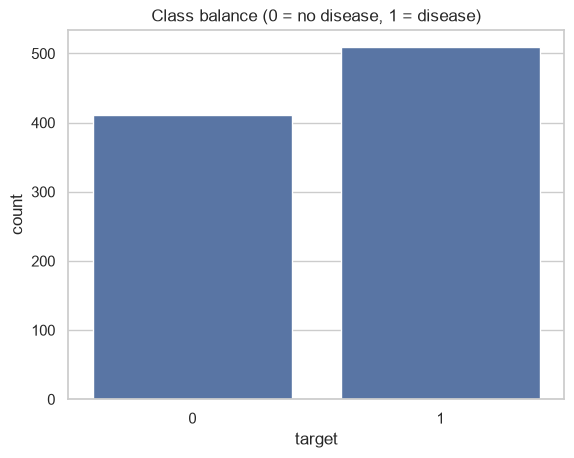

In [9]:
# 0 = no disease, 1–4 = disease present (different severities) -> binary
df["target"] = (df["num"] > 0).astype(int)

print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="target")
plt.title("Class balance (0 = no disease, 1 = disease)")
plt.show()

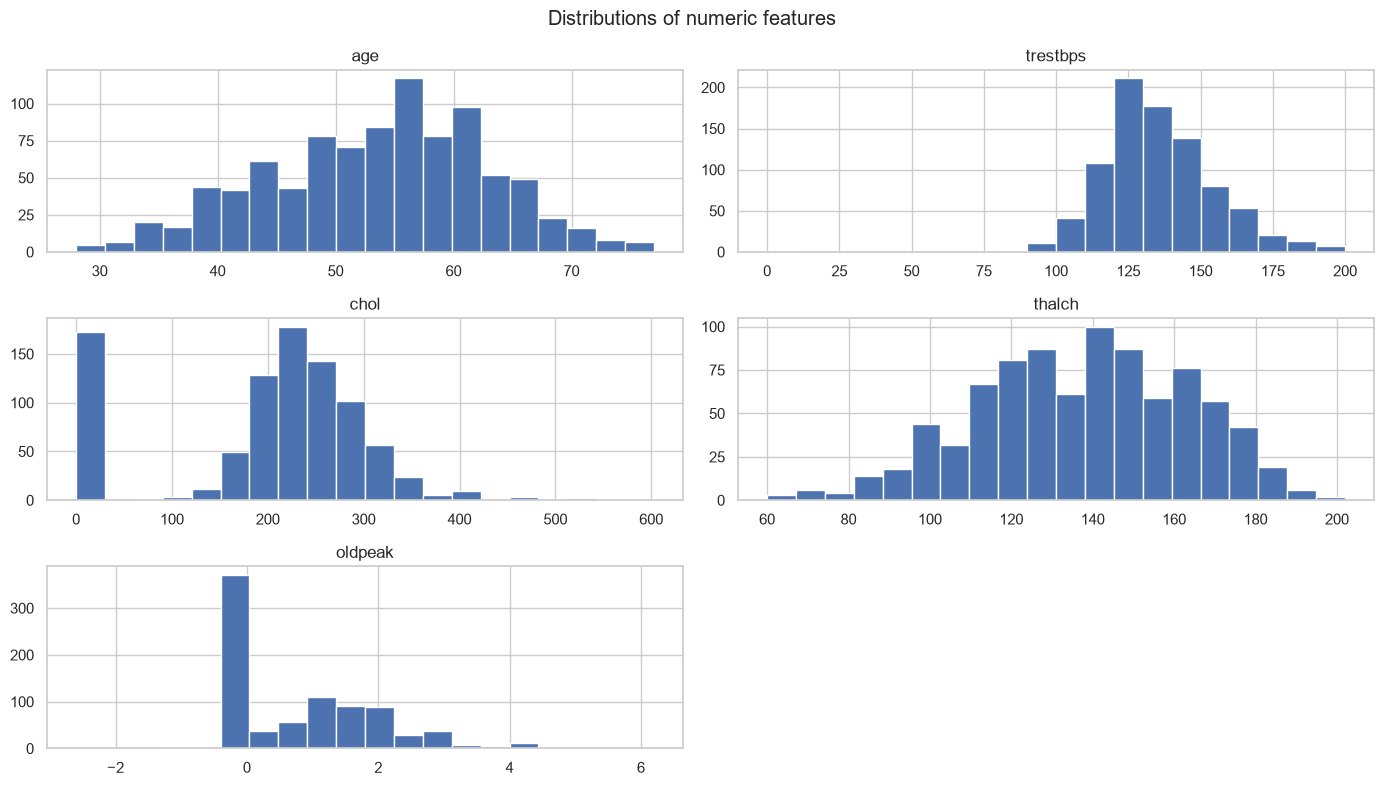

In [10]:
num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]

df[num_cols].hist(bins=20, figsize=(14, 8))
plt.suptitle("Distributions of numeric features")
plt.tight_layout()
plt.show()

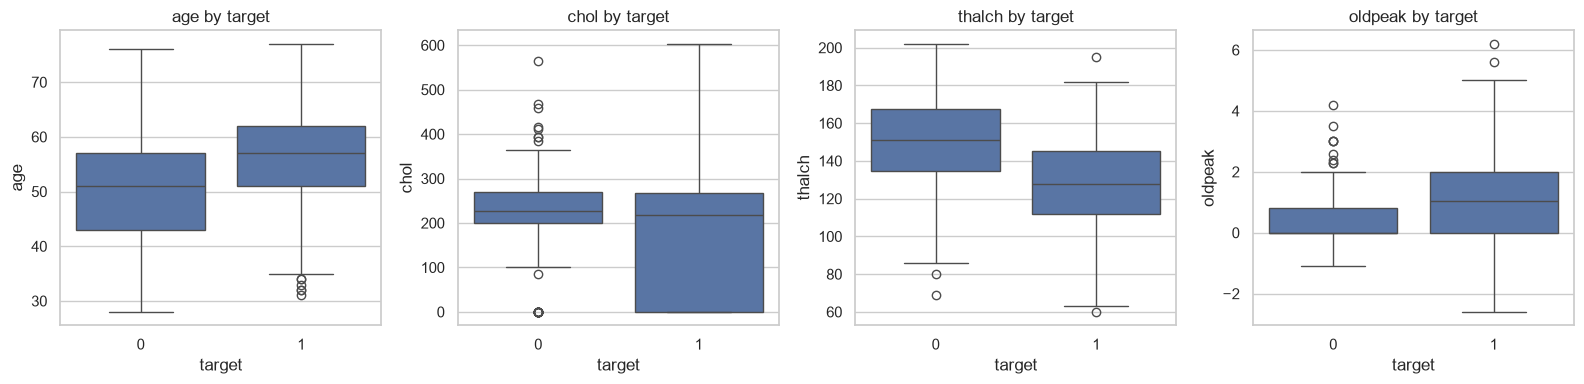

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["age", "chol", "thalch", "oldpeak"]):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} by target")
plt.tight_layout()
plt.show()

In [12]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal", "ca"]

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df.groupby(col, dropna=False)["target"].agg(["mean", "count"]).round(2))


--- sex ---
        mean  count
sex                
Female  0.26    194
Male    0.63    726

--- cp ---
                 mean  count
cp                          
asymptomatic     0.79    496
atypical angina  0.14    174
non-anginal      0.36    204
typical angina   0.43     46

--- fbs ---
       mean  count
fbs               
False  0.49    692
True   0.68    138
NaN    0.84     90

--- restecg ---
                  mean  count
restecg                      
lv hypertrophy    0.56    188
normal            0.51    551
st-t abnormality  0.66    179
NaN               1.00      2

--- exang ---
       mean  count
exang             
False  0.36    528
True   0.84    337
NaN    0.64     55

--- slope ---
             mean  count
slope                   
downsloping  0.78     63
flat         0.77    345
upsloping    0.38    203
NaN          0.38    309

--- thal ---
                   mean  count
thal                          
fixed defect       0.76     46
normal             0.30    196
rev

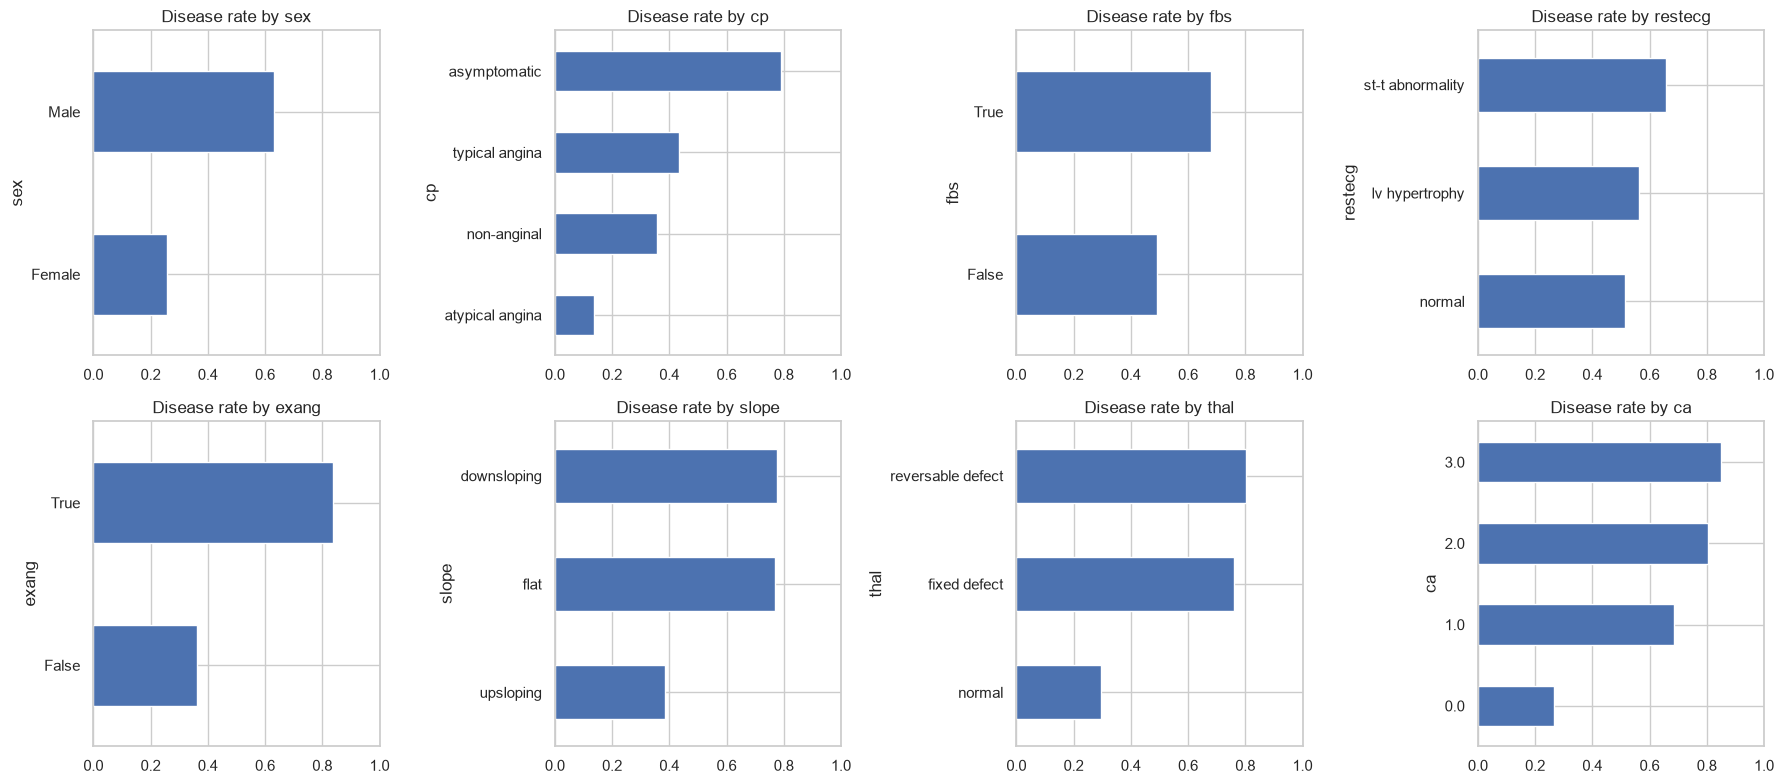

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cat_cols):
    df.groupby(col)["target"].mean().sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Disease rate by {col}")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [14]:
# Disease rate and patient count per hospital
df.groupby("dataset")["target"].agg(["mean", "count"]).round(2)

,mean,count
dataset,,
Cleveland,0.46,304
Hungary,0.36,293
Switzerland,0.93,123
VA Long Beach,0.74,200


In [15]:
# % missing per hospital, for the columns with missing values
cols_with_na = ["ca", "thal", "slope", "fbs", "oldpeak", "trestbps", "exang", "thalch", "chol"]
(df[cols_with_na].isnull().groupby(df["dataset"]).mean() * 100).round(0)

,ca,thal,slope,fbs,oldpeak,trestbps,exang,thalch,chol
dataset,,,,,,,,,
Cleveland,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Hungary,99.0,90.0,65.0,3.0,0.0,0.0,0.0,0.0,8.0
Switzerland,96.0,42.0,14.0,61.0,5.0,2.0,1.0,1.0,0.0
VA Long Beach,99.0,83.0,51.0,4.0,28.0,28.0,26.0,26.0,4.0


In [16]:
# Fake zeros in cholesterol per hospital
df.groupby("dataset")["chol"].apply(lambda s: (s == 0).sum())

dataset
Cleveland          0
Hungary            0
Switzerland      123
VA Long Beach     49
Name: chol, dtype: int64

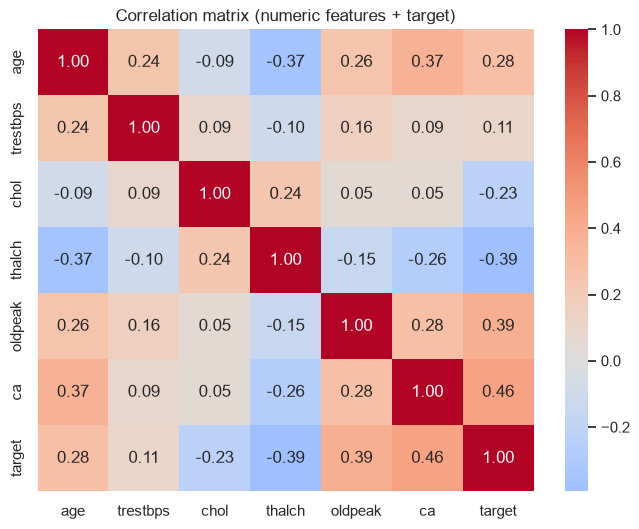

In [17]:
corr = df[num_cols + ["ca", "target"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features + target)")
plt.show()

In [18]:
corr["target"].drop("target").sort_values()

thalch     -0.394503
chol       -0.230583
trestbps    0.106233
age         0.282700
oldpeak     0.385528
ca          0.455599
Name: target, dtype: float64